# Student Performance Classification Models

This notebook trains and evaluates **5 classification models** on the Student Performance dataset:
1. Decision Tree
2. Support Vector Machine (SVM)
3. K-Nearest Neighbors (KNN)
4. Random Forest
5. Logistic Regression

**Target variable:** `final_grade` (A, B, C, D, F)

---
## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

print('All libraries imported successfully.')

All libraries imported successfully.


---
## 2. Load & Explore Data

In [6]:
df = pd.read_csv('student_performance_dataset.csv')
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (1000, 12)


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   str    
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    str    
 6   internet_access             1000 non-null   str    
 7   extracurricular_activities  1000 non-null   str    
 8   part_time_job               1000 non-null   str    
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   str    
dtypes: float64(5), int64(1), str(6)
memory usage: 93.9 KB


In [8]:
df.describe()

,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,3.570700,85.092300,6.799500,69.740900,83.543500
std,288.819436,1.478559,9.270685,1.203527,12.613425,10.341333
min,1.000000,0.500000,54.800000,3.200000,31.300000,46.800000
25%,250.750000,2.600000,78.800000,5.900000,61.000000,76.075000
50%,500.500000,3.600000,85.200000,6.800000,69.600000,83.800000
75%,750.250000,4.500000,91.900000,7.600000,78.400000,91.525000
max,1000.000000,8.100000,100.000000,10.000000,100.000000,100.000000


In [9]:
# Check for missing values
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
student_id                      0
gender                          0
study_time_hours                0
attendance_percent              0
sleep_hours                     0
parental_education            102
internet_access                 0
extracurricular_activities      0
part_time_job                   0
previous_grade                  0
final_exam_score                0
final_grade                     0
dtype: int64


Grade distribution:
final_grade
B    354
A    284
C    261
D     89
F     12
Name: count, dtype: int64


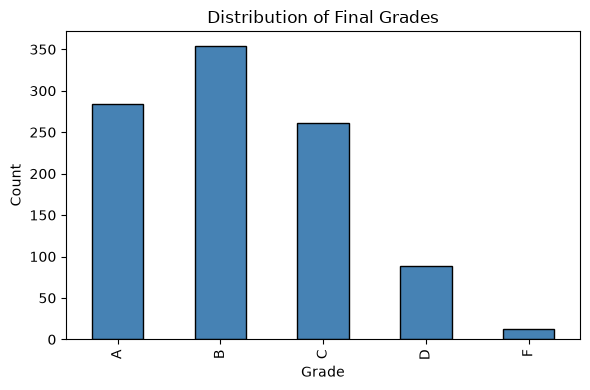

In [10]:
# Target variable distribution
print('Grade distribution:')
print(df['final_grade'].value_counts())

plt.figure(figsize=(6, 4))
df['final_grade'].value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Distribution of Final Grades')
plt.xlabel('Grade')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

---
## 3. Data Preprocessing

In [11]:
# Drop student_id (not a feature)
df = df.drop('student_id', axis=1)

# Encode categorical columns using LabelEncoder
label_encoders = {}
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('final_grade')  # encode target separately

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
    print(f'{col}: {list(le.classes_)}')

# Encode target
le_target = LabelEncoder()
df['final_grade'] = le_target.fit_transform(df['final_grade'])
print(f'\nTarget classes: {list(le_target.classes_)}')
print(f'Encoded as:     {list(range(len(le_target.classes_)))}')

gender: ['Female', 'Male']
parental_education: ['Bachelors', 'High School', 'Masters', 'PhD', nan]
internet_access: ['No', 'Yes']
extracurricular_activities: ['No', 'Yes']
part_time_job: ['No', 'Yes']

Target classes: ['A', 'B', 'C', 'D', 'F']
Encoded as:     [0, 1, 2, 3, 4]


In [12]:
# Split features and target
X = df.drop('final_grade', axis=1)
y = df['final_grade']

print(f'Features shape: {X.shape}')
print(f'Target shape:   {y.shape}')

Features shape: (1000, 10)
Target shape:   (1000,)


In [13]:
# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Testing set:  {X_test.shape[0]} samples')

Training set: 800 samples
Testing set:  200 samples


In [14]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Feature scaling applied.')

Feature scaling applied.


---
## 4. Helper Function for Evaluation

In [15]:
results = {}  # Store results for comparison

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    """Train, predict, and evaluate a model."""
    # Train
    model.fit(X_tr, y_tr)
    
    # Predict
    y_pred = model.predict(X_te)
    
    # Accuracy
    acc = accuracy_score(y_te, y_pred)
    results[name] = acc
    
    print(f'===== {name} =====')
    print(f'Accuracy: {acc:.4f} ({acc*100:.2f}%)')
    print()
    
    # Classification Report
    print('Classification Report:')
    print(classification_report(y_te, y_pred, target_names=le_target.classes_))
    
    # Confusion Matrix
    cm = confusion_matrix(y_te, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_target.classes_)
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{name} - Confusion Matrix')
    plt.tight_layout()
    plt.show()
    
    return model

---
## 5. Model 1: Decision Tree

===== Decision Tree =====
Accuracy: 0.9950 (99.50%)

Classification Report:
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        57
           B       1.00      1.00      1.00        71
           C       1.00      1.00      1.00        52
           D       1.00      0.94      0.97        18
           F       0.67      1.00      0.80         2

    accuracy                           0.99       200
   macro avg       0.93      0.99      0.95       200
weighted avg       1.00      0.99      1.00       200



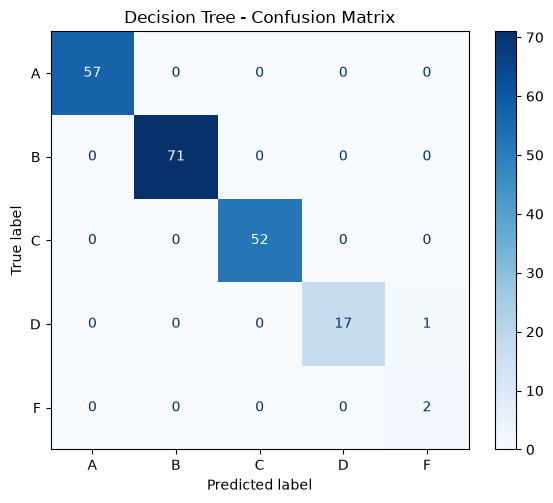

In [16]:
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model = evaluate_model(
    'Decision Tree', dt_model,
    X_train_scaled, X_test_scaled, y_train, y_test
)

---
## 6. Model 2: Support Vector Machine (SVM)

===== SVM =====
Accuracy: 0.8800 (88.00%)

Classification Report:
              precision    recall  f1-score   support

           A       0.95      0.91      0.93        57
           B       0.84      0.90      0.87        71
           C       0.87      0.87      0.87        52
           D       0.88      0.83      0.86        18
           F       0.00      0.00      0.00         2

    accuracy                           0.88       200
   macro avg       0.71      0.70      0.70       200
weighted avg       0.87      0.88      0.88       200



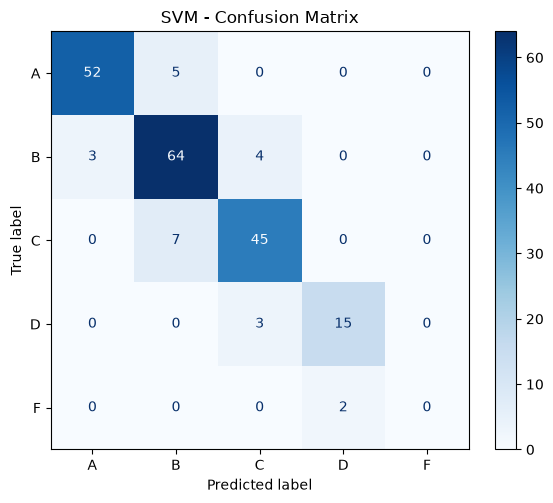

In [17]:
svm_model = SVC(
    kernel='rbf',
    C=10,
    gamma='scale',
    random_state=42
)

svm_model = evaluate_model(
    'SVM', svm_model,
    X_train_scaled, X_test_scaled, y_train, y_test
)

---
## 7. Model 3: K-Nearest Neighbors (KNN)

===== KNN =====
Accuracy: 0.7700 (77.00%)

Classification Report:
              precision    recall  f1-score   support

           A       0.83      0.86      0.84        57
           B       0.73      0.77      0.75        71
           C       0.73      0.77      0.75        52
           D       0.91      0.56      0.69        18
           F       0.00      0.00      0.00         2

    accuracy                           0.77       200
   macro avg       0.64      0.59      0.61       200
weighted avg       0.77      0.77      0.76       200



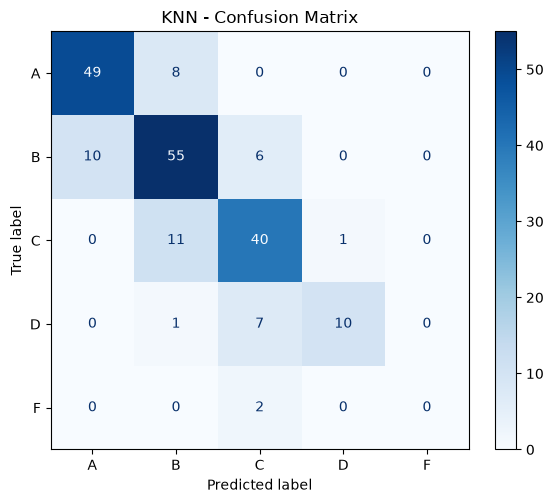

In [18]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights='distance',
    metric='minkowski'
)

knn_model = evaluate_model(
    'KNN', knn_model,
    X_train_scaled, X_test_scaled, y_train, y_test
)

---
## 8. Model 4: Random Forest

===== Random Forest =====
Accuracy: 0.9900 (99.00%)

Classification Report:
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        57
           B       1.00      1.00      1.00        71
           C       1.00      1.00      1.00        52
           D       0.90      1.00      0.95        18
           F       0.00      0.00      0.00         2

    accuracy                           0.99       200
   macro avg       0.78      0.80      0.79       200
weighted avg       0.98      0.99      0.99       200



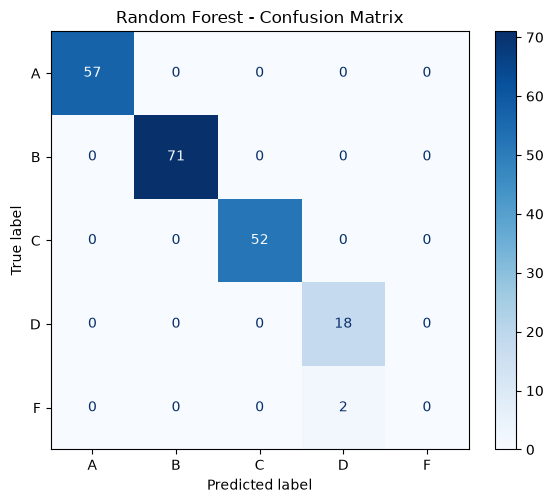

In [19]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

rf_model = evaluate_model(
    'Random Forest', rf_model,
    X_train_scaled, X_test_scaled, y_train, y_test
)

---
## 9. Model 5: Logistic Regression

===== Logistic Regression =====
Accuracy: 0.9450 (94.50%)

Classification Report:
              precision    recall  f1-score   support

           A       1.00      0.98      0.99        57
           B       0.91      1.00      0.95        71
           C       0.96      0.88      0.92        52
           D       0.89      0.89      0.89        18
           F       0.00      0.00      0.00         2

    accuracy                           0.94       200
   macro avg       0.75      0.75      0.75       200
weighted avg       0.94      0.94      0.94       200



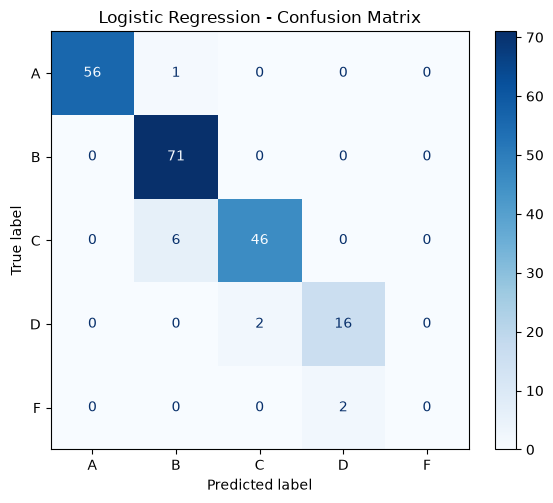

In [20]:
lr_model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    C=1.0,
    random_state=42
)

lr_model = evaluate_model(
    'Logistic Regression', lr_model,
    X_train_scaled, X_test_scaled, y_train, y_test
)

---
## 10. Model Comparison

In [21]:
# Comparison Table
comparison_df = pd.DataFrame({
    'Model': results.keys(),
    'Accuracy': results.values()
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

comparison_df['Accuracy (%)'] = (comparison_df['Accuracy'] * 100).round(2)
comparison_df.index = comparison_df.index + 1  # Start ranking from 1
comparison_df.index.name = 'Rank'

print('=== Model Comparison ===')
print(comparison_df[['Model', 'Accuracy (%)']])

=== Model Comparison ===
                    Model  Accuracy (%)
Rank                                   
1           Decision Tree          99.5
2           Random Forest          99.0
3     Logistic Regression          94.5
4                     SVM          88.0
5                     KNN          77.0


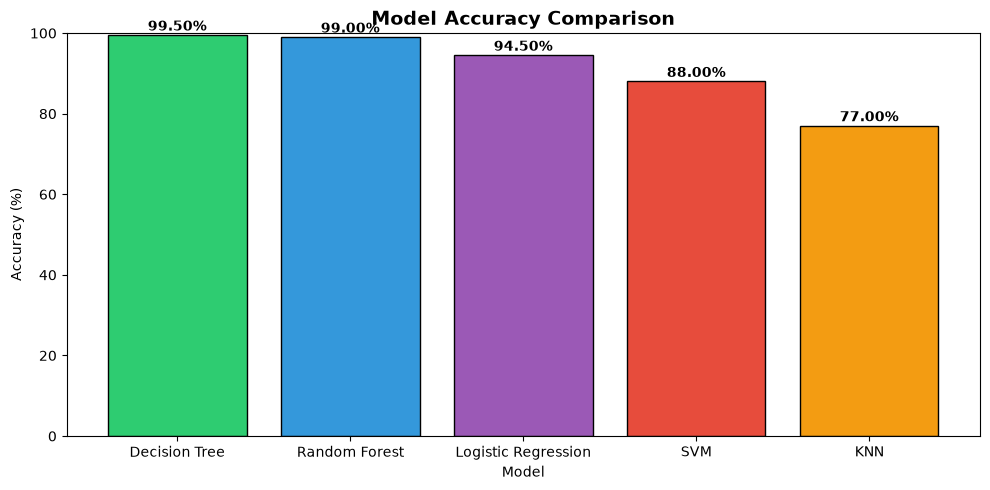

In [22]:
# Comparison Bar Chart
plt.figure(figsize=(10, 5))
colors = ['#2ecc71', '#3498db', '#9b59b6', '#e74c3c', '#f39c12']
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy (%)'], color=colors, edgecolor='black')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.3,
             f'{height:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [23]:
# Final Summary
best_model = comparison_df.iloc[0]['Model']
best_acc = comparison_df.iloc[0]['Accuracy (%)']

print(f'\nBest Performing Model: {best_model}')
print(f'Accuracy: {best_acc:.2f}%')


Best Performing Model: Decision Tree
Accuracy: 99.50%
